# Simulated Annealing Schedules

Michael Hahsler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [2]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [3]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [4]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [5]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

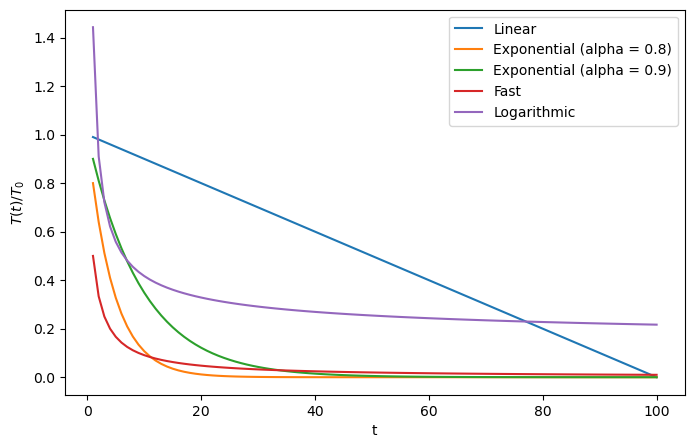

In [6]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

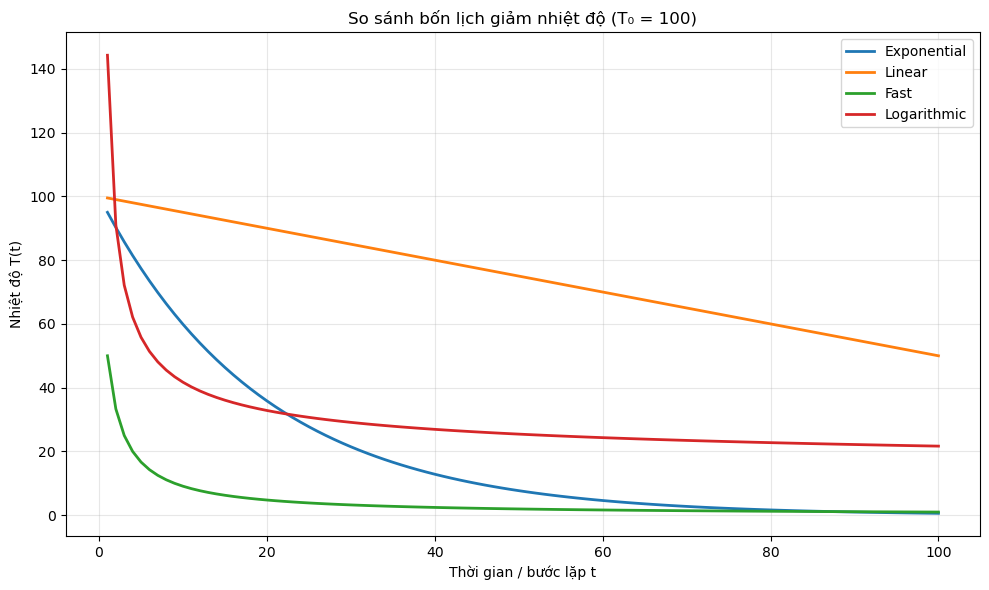

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Cùng T0 và khoảng thời gian cho cả bốn lịch nhiệt
T0 = 100
alpha = 0.95
eta = 0.5
t = np.arange(1, 101)  # t > 0 để logarithmic xác định

temperatures = {
    "Exponential": T0 * alpha**t,
    "Linear": T0 - eta * t,
    "Fast": T0 / (1 + t),
    "Logarithmic": T0 / np.log(1 + t),
}

plt.figure(figsize=(10, 6))

for name, values in temperatures.items():
    plt.plot(t, values, label=name, linewidth=2)

plt.title(f"So sánh bốn lịch giảm nhiệt độ (T₀ = {T0})")
plt.xlabel("Thời gian / bước lặp t")
plt.ylabel("Nhiệt độ T(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Nhận xét yêu cầu 2: So sánh các lịch giảm nhiệt độ

Đồ thị phía trên so sánh bốn lịch nhiệt với cùng tham số $T_0=100$ trên khoảng thời gian $t=1,\ldots,100$, sử dụng $\alpha=0.95$ và $\eta=0.5$.

- **Tuyến tính:** $T(t)=100-0.5t$, giảm đều từ $99.5$ tại $t=1$ xuống $50$ tại $t=100$; nhiệt độ vẫn dương trong toàn bộ khoảng khảo sát.
- **Mũ:** $T(t)=100(0.95)^t$, giảm từ $95$ xuống khoảng $0.59$.
- **Fast:** $T(t)=100/(1+t)$, giảm mạnh ở những bước đầu, từ $50$ xuống khoảng $0.99$.
- **Logarithmic:** $T(t)=100/\ln(1+t)$, giảm từ khoảng $144.27$ xuống $21.67$; duy trì nhiệt độ cao hơn lịch mũ và Fast trong khoảng khảo sát.

Các đường đều giảm nhưng có tốc độ và hình dạng khác nhau. Với cấu hình này, tại $t=100$, thứ tự nhiệt độ là tuyến tính > logarithmic > Fast > mũ. Thứ tự này phụ thuộc tham số và khoảng thời gian được chọn.

**Lưu ý:** Lịch logarithmic chỉ xác định khi $t>0$, nên cả bốn đường được vẽ từ $t=1$. Theo đúng công thức đề bài, cùng tham số $T_0$ không có nghĩa là cùng nhiệt độ tại bước đầu: $T_{\mathrm{log}}(1)=T_0/\ln 2>T_0$. Các số liệu nhận xét ở đây được tính từ công thức và tham số trong cell phía trên.

## Yêu cầu 3: Ảnh hưởng của alpha, eta và T0

Khảo sát từng tham số trong khi giữ các yếu tố còn lại cố định. Dùng $t=1,\ldots,300$ để quan sát cả giai đoạn nhiệt độ tuyến tính chạm 0.

Với bài toán **cực tiểu hóa**, một bước xấu làm tăng giá trị mục tiêu $\Delta E=f(x')-f(x)>0$ được chấp nhận với xác suất:

$$P(\text{chấp nhận bước xấu})=\exp\left(-\frac{\Delta E}{T(t)}\right),\quad T(t)>0.$$

Chọn **$\Delta E=5$ cố định** để so sánh ảnh hưởng riêng của lịch nhiệt. Đây là xác suất lý thuyết cho cùng một mức tăng hàm mục tiêu, chưa phải tỷ lệ chấp nhận đo từ một lần chạy SA. Khi lịch tuyến tính đạt $T\leq0$, coi quá trình làm nguội đã kết thúc và đặt xác suất chấp nhận bước xấu bằng 0; không đưa nhiệt độ âm vào công thức xác suất.

In [8]:
survey_time = np.arange(1, 301)
survey_T0 = 100
survey_alpha = 0.95
survey_eta = 0.5
delta_E = 5.0

def worse_acceptance(temperature, delta_energy=delta_E):
    """Xác suất cho bước xấu có delta_energy > 0; T <= 0 tương ứng dừng nguội."""
    temperature = np.asarray(temperature, dtype=float)
    exponent = np.full_like(temperature, -np.inf)
    np.divide(-delta_energy, temperature, out=exponent, where=temperature > 0)
    return np.exp(exponent)

def plot_parameter_survey(curves, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for label, temperature in curves.items():
        # Chặn tại 0 chỉ để biểu diễn giai đoạn đã kết thúc làm nguội.
        axes[0].plot(survey_time, np.maximum(temperature, 0), label=label)
        axes[1].plot(survey_time, worse_acceptance(temperature), label=label)
    axes[0].set_ylabel('Nhiệt độ T(t), hiển thị tối thiểu 0')
    axes[1].set_ylabel('P(chấp nhận bước xấu), ΔE = 5')
    axes[1].set_ylim(0, 1.02)
    for ax in axes:
        ax.set_xlabel('Bước lặp t')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### 3.1. Thay đổi alpha của lịch mũ

Giữ $T_0=100$, thử $\alpha\in\{0.90,0.95,0.99\}$.

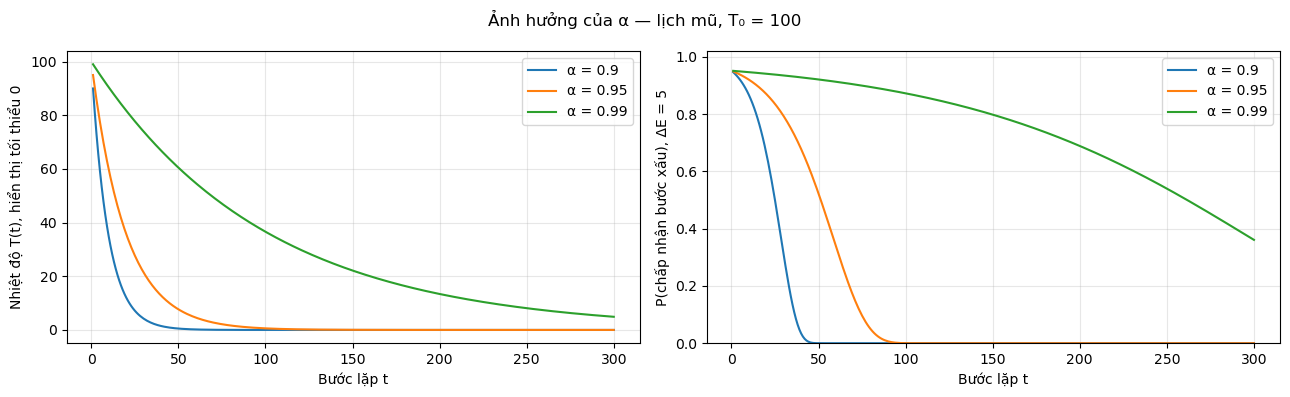

In [9]:
alpha_curves = {
    f'α = {value}': temperature_exponential(survey_time, survey_T0, value)
    for value in [0.90, 0.95, 0.99]
}
plot_parameter_survey(alpha_curves, 'Ảnh hưởng của α — lịch mũ, T₀ = 100')

**Nhận xét:** Với $0<\alpha<1$, alpha càng gần 1 thì nhiệt độ giảm càng chậm. Do đó $\alpha=0.99$ duy trì xác suất chấp nhận cùng một bước xấu cao hơn và lâu hơn $0.95$ và $0.90$. Ví dụ tại $t=100$, nhiệt độ tương ứng khoảng $36.60$, $0.59$, $0.00266$; với $\Delta E=5$, xác suất tương ứng khoảng $0.872$, $0.000215$ và gần 0.

### 3.2. Thay đổi eta của lịch tuyến tính

Giữ $T_0=100$, thử $\eta\in\{0.1,0.5,1.0\}$. Công thức gốc vẫn là $T(t)=T_0-\eta t$; đồ thị chỉ hiển thị tối thiểu bằng 0 sau khi quá trình làm nguội kết thúc.

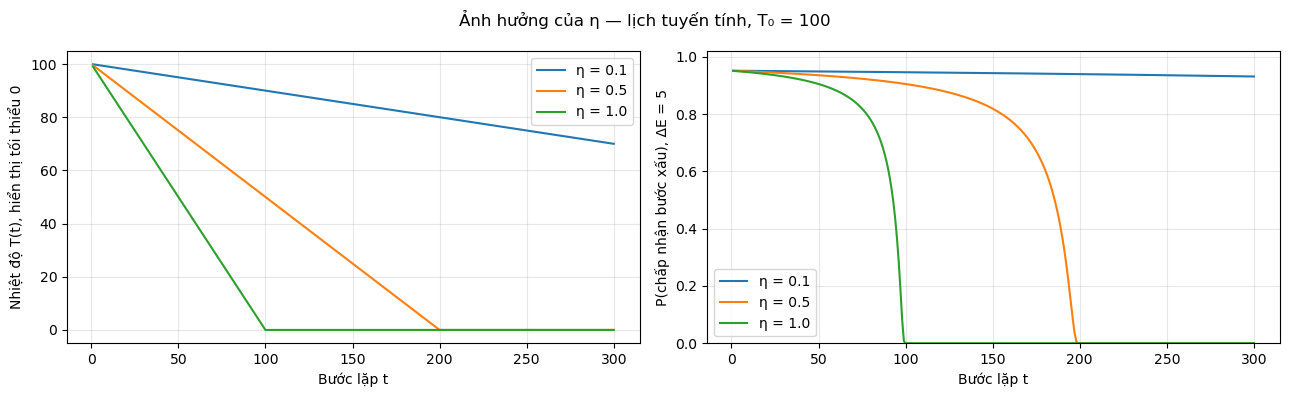

η = 0.1: nhiệt độ chạm 0 tại t = 1000
η = 0.5: nhiệt độ chạm 0 tại t = 200
η = 1.0: nhiệt độ chạm 0 tại t = 100


In [10]:
eta_curves = {
    f'η = {value}': temperature_linear(survey_time, survey_T0, value)
    for value in [0.1, 0.5, 1.0]
}
plot_parameter_survey(eta_curves, 'Ảnh hưởng của η — lịch tuyến tính, T₀ = 100')
for value in [0.1, 0.5, 1.0]:
    print(f'η = {value}: nhiệt độ chạm 0 tại t = {survey_T0 / value:g}')

**Nhận xét:** Eta càng nhỏ thì mức giảm nhiệt mỗi bước càng nhỏ, nên thuật toán có thể chấp nhận bước xấu lâu hơn. Nhiệt độ chạm 0 tại $t=T_0/\eta$: lần lượt là $1000$, $200$, $100$ với eta bằng $0.1$, $0.5$, $1.0$. Trong khoảng khảo sát 300 bước, eta bằng $0.1$ vẫn giữ nhiệt độ dương, còn hai cấu hình kia đã kết thúc làm nguội. Tại $t=100$, xác suất với $\Delta E=5$ lần lượt khoảng $0.946$, $0.905$ và 0 theo quy ước dừng.

### 3.3. Thay đổi T0 trên cả bốn lịch nhiệt

Thử $T_0\in\{50,100,200\}$; giữ $\alpha=0.95$, $\eta=0.5$. Cùng miền thời gian và cùng $\Delta E=5$ cho tất cả cấu hình.

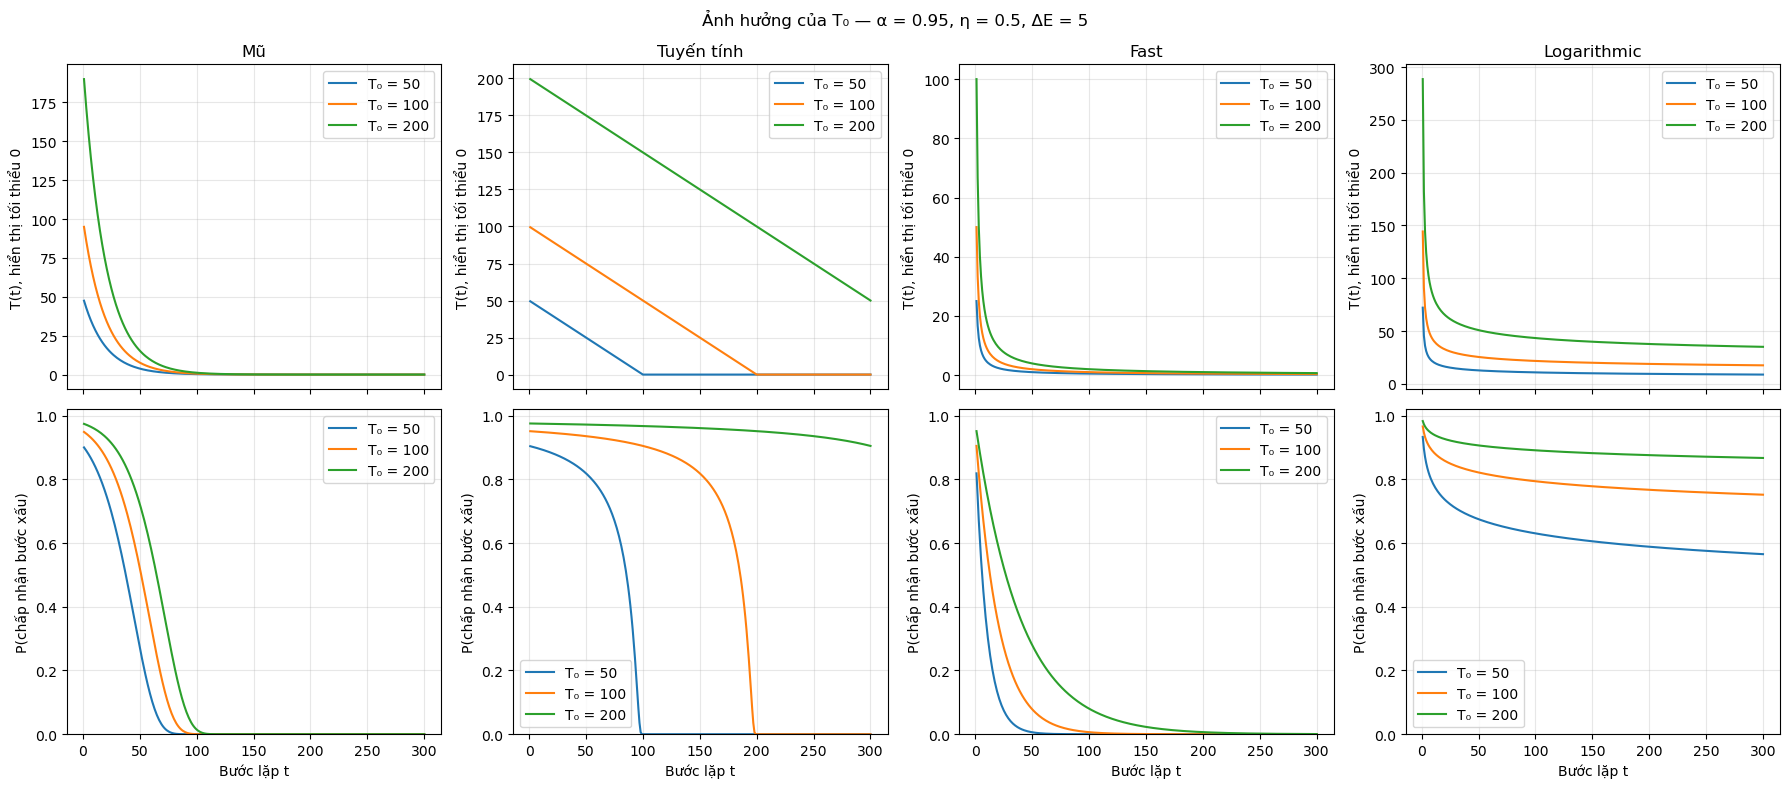

In [11]:
survey_schedules = {
    'Mũ': lambda steps, start: temperature_exponential(steps, start, survey_alpha),
    'Tuyến tính': lambda steps, start: temperature_linear(steps, start, survey_eta),
    'Fast': temperature_fast,
    'Logarithmic': temperature_logarithmic,
}

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
for column, (name, schedule) in enumerate(survey_schedules.items()):
    for start in [50, 100, 200]:
        temperature = schedule(survey_time, start)
        axes[0, column].plot(survey_time, np.maximum(temperature, 0), label=f'T₀ = {start}')
        axes[1, column].plot(survey_time, worse_acceptance(temperature), label=f'T₀ = {start}')
    axes[0, column].set_title(name)
    axes[0, column].set_ylabel('T(t), hiển thị tối thiểu 0')
    axes[1, column].set_ylabel('P(chấp nhận bước xấu)')
    axes[1, column].set_xlabel('Bước lặp t')
    axes[1, column].set_ylim(0, 1.02)
    for row in range(2):
        axes[row, column].grid(alpha=0.3)
        axes[row, column].legend()
fig.suptitle('Ảnh hưởng của T₀ — α = 0.95, η = 0.5, ΔE = 5')
fig.tight_layout()
plt.show()

**Nhận xét:** Trong cùng một lịch, tại cùng thời điểm và cùng mức tăng $\Delta E$, $T_0$ lớn hơn cho nhiệt độ cao hơn và xác suất chấp nhận bước xấu lớn hơn khi nhiệt độ còn dương. Với lịch tuyến tính, tăng $T_0$ còn kéo dài thời gian trước khi chạm 0: $100$, $200$, $400$ bước tương ứng với $T_0=50,100,200$ và $\eta=0.5$.

### 3.4. Đối chiếu thời gian còn chấp nhận bước xấu

So sánh bốn lịch với cấu hình chung $T_0=100$, $\alpha=0.95$, $\eta=0.5$. Dùng ngưỡng minh họa **$P\geq0.1$** để định lượng “chấp nhận bước xấu lâu hơn”; ngưỡng này chỉ phục vụ phân tích, không thay đổi quy tắc SA. Với $\Delta E=5$, điều kiện này tương đương $T\geq5/\ln 10\approx2.17$.

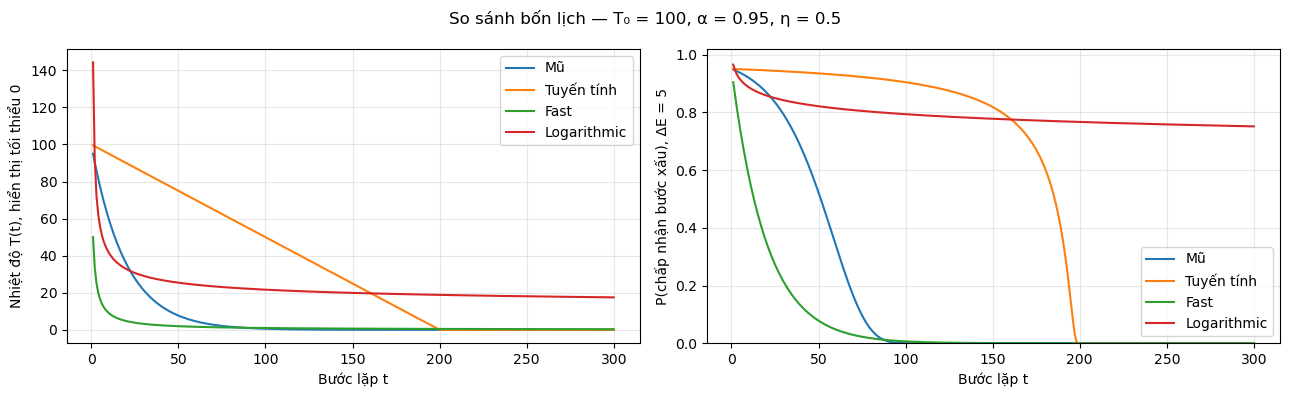

Bước cuối có P >= 0.1 trong miền t = 1..300 (ΔE = 5):
Mũ          : 74
Tuyến tính  : 195
Fast        : 45
Logarithmic : 300 (vẫn đạt ngưỡng ở cuối miền khảo sát)


In [12]:
baseline_curves = {
    name: schedule(survey_time, survey_T0)
    for name, schedule in survey_schedules.items()
}
plot_parameter_survey(baseline_curves, 'So sánh bốn lịch — T₀ = 100, α = 0.95, η = 0.5')

probability_threshold = 0.1
print('Bước cuối có P >= 0.1 trong miền t = 1..300 (ΔE = 5):')
for name, temperature in baseline_curves.items():
    probability = worse_acceptance(temperature)
    eligible_steps = survey_time[probability >= probability_threshold]
    last_step = str(eligible_steps[-1]) if eligible_steps.size else 'không có'
    note = ' (vẫn đạt ngưỡng ở cuối miền khảo sát)' if probability[-1] >= probability_threshold else ''
    print(f'{name:<12}: {last_step}{note}')

### Kết luận yêu cầu 3

- **Alpha lớn hơn (gần 1), eta nhỏ hơn, T0 lớn hơn** giúp duy trì khả năng chấp nhận cùng một bước xấu lâu hơn trong từng phép so sánh tương ứng.
- Với cấu hình ở mục 3.4 và $\Delta E=5$, bước cuối đạt $P\geq0.1$ là **74** với lịch mũ, **195** với tuyến tính, **45** với Fast. Logarithmic vẫn đạt ngưỡng tại bước **300**, nên chưa xác định được bước cuối thực sự trong miền khảo sát này.
- Trong thí nghiệm này, **logarithmic duy trì khả năng chấp nhận bước xấu lâu nhất** theo tiêu chí đã chọn. Logarithmic giảm chậm về dài hạn; tuy nhiên không thể suy ra nó luôn có nhiệt độ cao nhất ở mọi bước, hay luôn cho nghiệm tốt nhất. Ví dụ lịch tuyến tính vẫn có thể nóng hơn logarithmic ở một phần khoảng chạy.
- Giảm nhiệt chậm tạo cơ hội thoát cực trị cục bộ lâu hơn, nhưng với ngân sách hữu hạn cũng có thể làm chậm việc ổn định nghiệm. Để kết luận chất lượng nghiệm và thời gian thực tế, cần chạy SA trên bài toán Bài 4 ở yêu cầu tiếp theo.

## Yêu cầu 4: So sánh lịch nhiệt trong SA của Bài 4 (n-Queens)

### Thiết kế thí nghiệm

- Dùng **chung hàm SA** với Task 5 của [n_queens.ipynb](n_queens.ipynb), cài đặt trong [n_queens_sa.py](n_queens_sa.py). Hàm mục tiêu là số cặp hậu xung đột; hàng xóm chuyển một hậu sang hàng khác trong cùng cột.
- Chạy **30 lần cho mỗi lịch và mỗi kích thước $n=4,8$**. Trong mỗi lần thử, các lịch dùng cùng bàn cờ ban đầu và cùng seed thuật toán. Bàn cờ được tạo bằng seed `202600 + 1000*n + trial`; seed thuật toán là `500000 + 1000*n + trial`.
- Ngân sách tối đa **5.000 bước** mỗi lần chạy. Dừng sớm nếu tìm được $f=0$ hoặc $T\leq0$; cùng quy tắc cho mọi lịch. Chấp nhận bước ngang bằng ($\Delta=0$).
- Cùng tham số **$T_0=5$**, lịch mũ dùng **$\alpha=0.995$**, tuyến tính dùng **$\eta=5/5001$**, Fast và logarithmic theo đúng các hàm đã định nghĩa. Tuyến tính vẫn dương trong toàn bộ ngân sách. Giá trị $T_0$ ở đây được chọn theo đơn vị xung đột của n-Queens, khác bộ tham số minh họa ở yêu cầu 2–3.
- Đo bằng `perf_counter` quanh lời gọi SA, gồm khởi tạo RNG, đếm xung đột và lưu lịch sử; không gồm tạo bàn cờ, vẽ hình, tổng hợp bảng hay nạp module. Luân phiên thứ tự chạy các lịch giữa các lần thử để giảm ảnh hưởng thứ tự.
- Chất lượng được đánh giá bằng **f tốt nhất**, độ lệch chuẩn và tỷ lệ tìm được $f=0$; thời gian báo cáo trung bình và độ lệch chuẩn, kèm số bước thực tế. Thời gian là thời gian tới nghiệm hoặc tới điều kiện dừng, không phải tất cả các lần đều chạy đủ ngân sách.

**Lưu ý:** Cùng tham số $T_0$ nhưng các lịch có $T(1)$ khác nhau theo công thức đề, đặc biệt logarithmic có $T(1)>T_0$. Đây là so sánh cấu hình cụ thể, chưa phải tối ưu tham số cho từng lịch.

In [13]:
from pathlib import Path
import sys

lab_directory = next(
    directory for directory in [Path.cwd(), Path.cwd() / 'weekly assignments/lab03 - local search']
    if (directory / 'n_queens_sa.py').is_file()
)
if str(lab_directory) not in sys.path:
    sys.path.insert(0, str(lab_directory))
from n_queens_sa import simulated_annealing as anneal_queens
from n_queens_sa import conflicts as sa_conflicts

import pandas as pd
from time import perf_counter
from IPython.display import display, Markdown

benchmark_steps = 5000
benchmark_repeats = 30
benchmark_T0 = 5.0
benchmark_alpha = 0.995
benchmark_eta = benchmark_T0 / (benchmark_steps + 1)
benchmark_schedules = {
    'Mũ': lambda t: temperature_exponential(t, benchmark_T0, benchmark_alpha),
    'Tuyến tính': lambda t: temperature_linear(t, benchmark_T0, benchmark_eta),
    'Fast': lambda t: temperature_fast(t, benchmark_T0),
    'Logarithmic': lambda t: temperature_logarithmic(t, benchmark_T0),
}

# Khởi động trước phần đo; không tính chi phí import/khởi động vào số liệu.
anneal_queens([0, 0, 0, 0], benchmark_schedules['Mũ'], max_steps=10, seed=0)
benchmark_records = []
benchmark_runs = {}
schedule_names = list(benchmark_schedules)
for n in [4, 8]:
    for trial in range(benchmark_repeats):
        initial_seed = 202600 + 1000 * n + trial
        algorithm_seed = 500000 + 1000 * n + trial
        initial_board = np.random.default_rng(initial_seed).integers(0, n, size=n)
        saved_initial = initial_board.copy()
        shift = trial % len(schedule_names)
        order = schedule_names[shift:] + schedule_names[:shift]
        for name in order:
            started = perf_counter()
            run = anneal_queens(initial_board, benchmark_schedules[name],
                                max_steps=benchmark_steps, seed=algorithm_seed)
            elapsed_ms = (perf_counter() - started) * 1000
            assert np.array_equal(initial_board, saved_initial)
            assert run['best_f'] == sa_conflicts(run['best_board'])
            assert np.all(np.diff(run['best_history']) <= 0)
            assert run['steps'] <= benchmark_steps
            benchmark_runs[n, trial, name] = run
            benchmark_records.append({
                'n': n, 'schedule': name, 'trial': trial,
                'initial_seed': initial_seed, 'algorithm_seed': algorithm_seed,
                'initial_f': sa_conflicts(initial_board),
                'best_f': run['best_f'], 'final_f': run['final_f'],
                'success': run['best_f'] == 0,
                'runtime_ms': elapsed_ms, 'steps': run['steps'],
                'worse_proposed': run['worse_proposed'],
                'worse_accepted': run['worse_accepted'],
            })

benchmark_results = pd.DataFrame(benchmark_records)
benchmark_summary = benchmark_results.groupby(['n', 'schedule']).agg(
    runs=('best_f', 'size'),
    best_f=('best_f', 'min'), mean_f=('best_f', 'mean'), std_f=('best_f', 'std'),
    successes=('success', 'sum'), success_rate=('success', 'mean'),
    mean_ms=('runtime_ms', 'mean'), std_ms=('runtime_ms', 'std'),
    mean_steps=('steps', 'mean'),
).reindex(pd.MultiIndex.from_product([[4, 8], schedule_names], names=['n', 'schedule']))

comparison_table = pd.DataFrame({
    'Số lần': benchmark_summary['runs'],
    'f tốt nhất': benchmark_summary['best_f'],
    'f trung bình ± SD': [f'{m:.3f} ± {s:.3f}' for m, s in zip(benchmark_summary.mean_f, benchmark_summary.std_f)],
    'Giải được / tổng': [f'{int(k)}/{int(r)}' for k, r in zip(benchmark_summary.successes, benchmark_summary.runs)],
    'Thành công (%)': 100 * benchmark_summary['success_rate'],
    'Thời gian (ms), TB ± SD': [f'{m:.3f} ± {s:.3f}' for m, s in zip(benchmark_summary.mean_ms, benchmark_summary.std_ms)],
    'Số bước TB': benchmark_summary['mean_steps'],
})
display(comparison_table.round(2))

Số lần  f tốt nhất f trung bình ± SD Giải được / tổng  \
n schedule                                                             
4 Mũ               30           0     0.000 ± 0.000            30/30   
  Tuyến tính       30           0     0.000 ± 0.000            30/30   
  Fast             30           0     0.000 ± 0.000            30/30   
  Logarithmic      30           0     0.000 ± 0.000            30/30   
8 Mũ               30           0     0.000 ± 0.000            30/30   
  Tuyến tính       30           0     0.333 ± 0.479            20/30   
  Fast             30           0     0.000 ± 0.000            30/30   
  Logarithmic      30           0     0.033 ± 0.183            29/30   

               Thành công (%) Thời gian (ms), TB ± SD  Số bước TB  
n schedule                                                         
4 Mũ                   100.00           2.406 ± 1.915       93.10  
  Tuyến tính           100.00           3.024 ± 2.972      111.23  
  Fast                 100.00           1.053 ± 0.810       37.70  
  Logarithmic          100.00           2.287 ± 1.919       71.70  
8 Mũ                   100.00         46.919 ± 30.426     1140.67  
  Tuyến tính            66.67        181.495 ± 55.583     4270.27  
  Fast                 100.00         26.283 ± 35.397      599.03  
  Logarithmic           96.67         89.418 ± 66.829     1846.07

### Hội tụ và tỷ lệ thành công

Đồ thị trái lấy trung bình **f tốt nhất** qua 30 lần chạy. Với lần dừng sớm, giữ nguyên f tốt nhất tới hết trục 5.000 bước để các đường có cùng chiều dài. Đây chỉ là cách tổng hợp đồ thị; số bước và thời gian trong bảng vẫn là số thực đo.

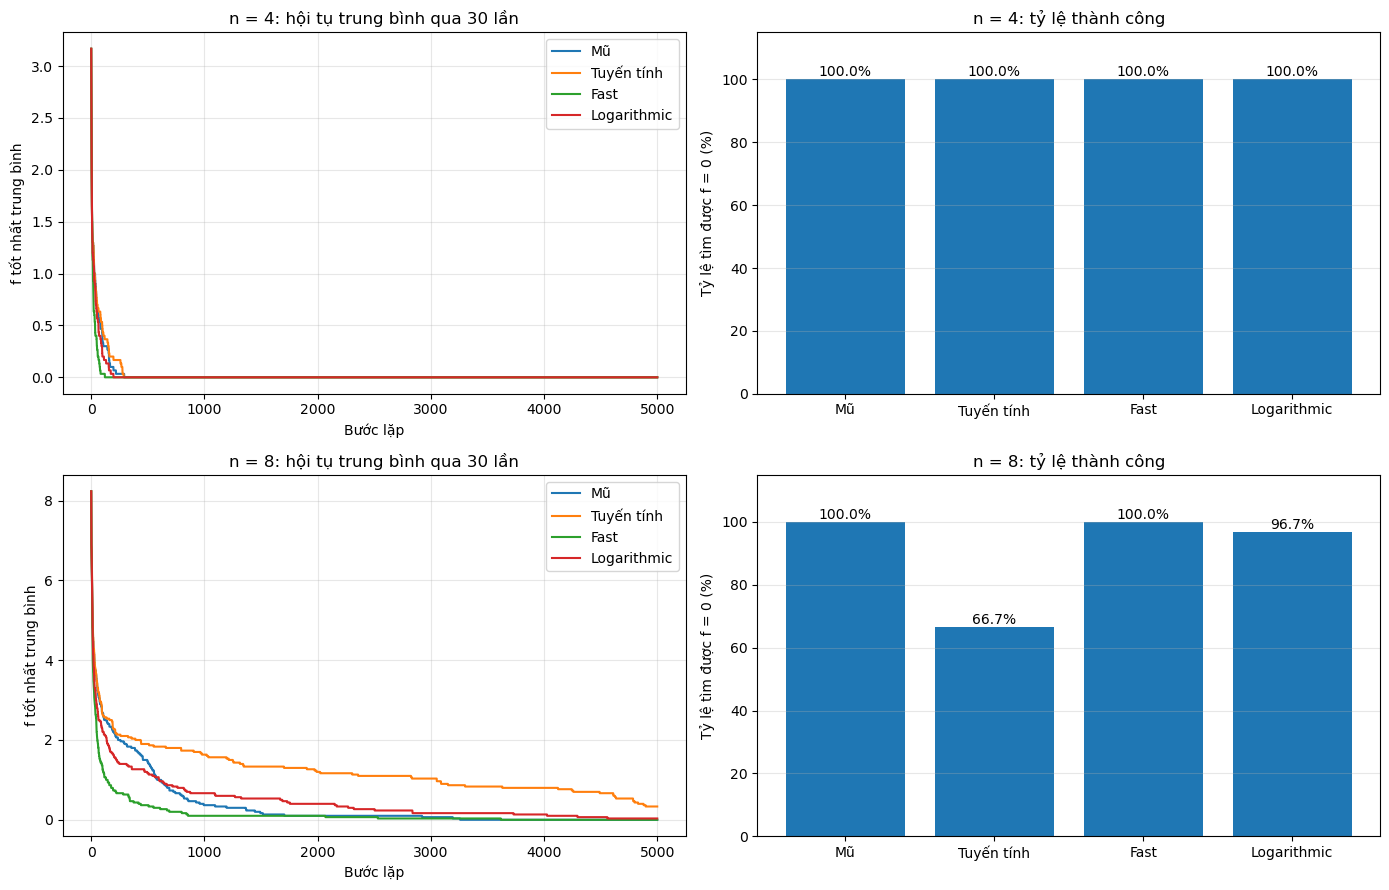

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, n in enumerate([4, 8]):
    for name in schedule_names:
        histories = []
        for trial in range(benchmark_repeats):
            history = benchmark_runs[n, trial, name]['best_history']
            histories.append(np.pad(history, (0, benchmark_steps + 1 - len(history)), mode='edge'))
        axes[row, 0].plot(np.mean(histories, axis=0), label=name)
    axes[row, 0].set_title(f'n = {n}: hội tụ trung bình qua {benchmark_repeats} lần')
    axes[row, 0].set_xlabel('Bước lặp')
    axes[row, 0].set_ylabel('f tốt nhất trung bình')
    axes[row, 0].grid(alpha=0.3)
    axes[row, 0].legend()
    rates = 100 * benchmark_summary.loc[n, 'success_rate'].to_numpy()
    bars = axes[row, 1].bar(schedule_names, rates)
    axes[row, 1].bar_label(bars, fmt='%.1f%%')
    axes[row, 1].set_ylim(0, 115)
    axes[row, 1].set_ylabel('Tỷ lệ tìm được f = 0 (%)')
    axes[row, 1].set_title(f'n = {n}: tỷ lệ thành công')
    axes[row, 1].grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()

### Nhận xét từ kết quả thực nghiệm

Cell dưới sinh nhận xét từ bảng kết quả thực tế; chạy lại notebook sẽ cập nhật cả số liệu và nhận xét. Nghiệm tốt nhất đạt 0 là lời giải hợp lệ của n-Queens, không chỉ là cải thiện so với bàn cờ ban đầu.

In [15]:
discussion = []
for n in [4, 8]:
    table = benchmark_summary.loc[n]
    highest_rate = table.success_rate.max()
    leaders = table.index[table.success_rate == highest_rate].tolist()
    fastest = table.mean_ms.idxmin()
    discussion.append(
        f'- **n = {n}:** Tỷ lệ thành công cao nhất là **{100 * highest_rate:.1f}%**, '
        f'thuộc các lịch **{", ".join(leaders)}**. '
        f'Thời gian trung bình nhỏ nhất là **{fastest}**, '
        f'**{table.loc[fastest, "mean_ms"]:.3f} ms**; '
        'cần đọc cùng tỷ lệ thành công vì một lần thất bại có thể dừng hoặc đóng băng sớm.'
    )
    for name in schedule_names:
        item = table.loc[name]
        discussion.append(
            f'  - {name}: giải được {int(item.successes)}/{int(item.runs)} lần, '
            f'f tốt nhất trung bình {item.mean_f:.3f}, '
            f'{item.mean_steps:.1f} bước và {item.mean_ms:.3f} ms trung bình.'
        )
discussion.append(
    '\n**Diễn giải:** Lịch Fast hạ nhiệt nhanh có thể hạn chế cơ hội thoát cực trị cục bộ; '
    'logarithmic giữ khả năng chấp nhận bước xấu lâu hơn nhưng có thể cần nhiều bước để ổn định. '
    'Tốc độ làm nguội chậm không tự bảo đảm tỷ lệ thành công cao nhất trong ngân sách hữu hạn. '
    'Chỉ kết luận theo các cấu hình, seed và kích thước đã thử; 30 lần chạy là ước lượng hữu hạn, '
    'thời gian có thể thay đổi theo máy và tải hệ thống.'
)
display(Markdown('\n'.join(discussion)))

- **n = 4:** Tỷ lệ thành công cao nhất là **100.0%**, thuộc các lịch **Mũ, Tuyến tính, Fast, Logarithmic**. Thời gian trung bình nhỏ nhất là **Fast**, **1.053 ms**; cần đọc cùng tỷ lệ thành công vì một lần thất bại có thể dừng hoặc đóng băng sớm.
  - Mũ: giải được 30/30 lần, f tốt nhất trung bình 0.000, 93.1 bước và 2.406 ms trung bình.
  - Tuyến tính: giải được 30/30 lần, f tốt nhất trung bình 0.000, 111.2 bước và 3.024 ms trung bình.
  - Fast: giải được 30/30 lần, f tốt nhất trung bình 0.000, 37.7 bước và 1.053 ms trung bình.
  - Logarithmic: giải được 30/30 lần, f tốt nhất trung bình 0.000, 71.7 bước và 2.287 ms trung bình.
- **n = 8:** Tỷ lệ thành công cao nhất là **100.0%**, thuộc các lịch **Mũ, Fast**. Thời gian trung bình nhỏ nhất là **Fast**, **26.283 ms**; cần đọc cùng tỷ lệ thành công vì một lần thất bại có thể dừng hoặc đóng băng sớm.
  - Mũ: giải được 30/30 lần, f tốt nhất trung bình 0.000, 1140.7 bước và 46.919 ms trung bình.
  - Tuyến tính: giải được 20/30 lần, f tốt nhất trung bình 0.333, 4270.3 bước và 181.495 ms trung bình.
  - Fast: giải được 30/30 lần, f tốt nhất trung bình 0.000, 599.0 bước và 26.283 ms trung bình.
  - Logarithmic: giải được 29/30 lần, f tốt nhất trung bình 0.033, 1846.1 bước và 89.418 ms trung bình.

**Diễn giải:** Lịch Fast hạ nhiệt nhanh có thể hạn chế cơ hội thoát cực trị cục bộ; logarithmic giữ khả năng chấp nhận bước xấu lâu hơn nhưng có thể cần nhiều bước để ổn định. Tốc độ làm nguội chậm không tự bảo đảm tỷ lệ thành công cao nhất trong ngân sách hữu hạn. Chỉ kết luận theo các cấu hình, seed và kích thước đã thử; 30 lần chạy là ước lượng hữu hạn, thời gian có thể thay đổi theo máy và tải hệ thống.

## Tổng kết Bài 5

1. Đã định nghĩa và chạy bốn hàm `temperature_exponential`, `temperature_linear`, `temperature_fast`, `temperature_logarithmic`.
2. Đã vẽ T(t) với cùng tham số $T_0$ và miền thời gian; logarithmic chỉ được gọi khi $t>0$.
3. Đã thay đổi alpha, eta, T0; đối chiếu nhiệt độ và xác suất chấp nhận cùng mức tăng $\Delta E=5$, kèm nhận xét và xử lý nhiệt độ tuyến tính không dương.
4. Đã dùng chung SA của Bài 4 (n-Queens), so sánh **bốn lịch** với **30 lần trên mỗi $n=4,8$**, báo cáo chất lượng nghiệm, tỷ lệ thành công, thời gian và hội tụ.

**Giải thích kết quả:** Fast vẫn có thể di chuyển trên vùng bằng phẳng vì thuật toán luôn chấp nhận bước có $\Delta=0$, ngay cả khi nhiệt độ đã rất thấp. Do đó giảm nhiệt nhanh không đồng nghĩa với ngừng tìm kiếm. Lịch tuyến tính giảm chậm có thể dành phần lớn ngân sách cho việc khám phá; cần đọc kết quả trong bảng thay vì suy ra lịch nóng lâu hơn luôn tốt hơn.

**Kết luận chung:** Alpha gần 1 hơn, eta nhỏ hơn và T0 lớn hơn duy trì khả năng chấp nhận bước xấu lâu hơn trong từng phép so sánh. Chọn lịch cho bài toán cụ thể cần cân bằng khám phá và ổn định nghiệm; bảng thực nghiệm phía trên là căn cứ đánh giá trong ngân sách đã chọn.

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)